**Cell 1**

# Role 2 - Waveform simulation, injection, and label EDA

**Owner: Aaron Rassiq**

Create labeled observations from physical parameters and real noise. You own parameter draws, waveform generation, placement, target derivation, SNR accounting and accepted-population EDA. Your checkpoint deliverable is data evidence, not a trained model.

Revised scope: dataset preparation, preprocessing and EDA. This is a new notebook; earlier role notebooks are preserved. Every implementation cell is deliberately empty.

**Cell 2**

## What this milestone covers

The project question remains whether four-parameter inference generalizes from O3a H1 noise to O4a H1 noise. This checkpoint concentrates on preparing and understanding the dataset: source provenance, physical labels, preprocessing, actual split counts, EDA, plots, and limitations. Model training, model performance tables and calibration conclusions are outside this notebook set's required work.

The methodology section must still describe three algorithms because the rubric asks for a baseline and two improvements: linear regression, its small regularized extension Ridge, and SNPE with a masked autoregressive flow. Describe them as the next common comparison; do not invent new training results. Feature importance is explicitly requested by the rubric. Input-target association is useful EDA but does not fully substitute for model-based importance; Role 4 must state this gap honestly if importance is deferred.

**Existing evidence versus your work:** The repository already contains saved noise, injections and processed data. The revised PDF uses those artifacts, not results from these new notebooks. Your task is a separately identified manual pilot. Do not claim your pilot has the old dataset's 800-per-run counts until you actually generate and check them. The earlier split was a 750-row O3a development pool, 50 O3a held-out examples and 800 O4a evaluation examples. A 600/150 subdivision of the development pool is a proposal, not a completed split.

**Implementation rule:** Write your own code in the empty cells. You may call standard scientific libraries and consult their documentation, but do not import ligo_pipeline, project utils, config.py, another notebook's implementation, or prepared training/model checkpoints. Trusted raw strain with source metadata is allowed. You may write your own small functions after explaining their steps. No solution code is supplied here.

**Ownership:** Assign one person per notebook; names are unassigned. Review each other's outputs, but let each owner make their own notebook changes. Record actual contributions and dates. Every cell has a sequential cell_number and every markdown cell displays its number; the preceding task labels the empty code cell. Renumber all cells from 1 when inserting new cells. Execution counters are not stable cell numbering.


**Cell 3**

## Common contract and parallel work

Agree on one small experiment before scaling up: H1; O3a development and within-run evaluation; O4a cross-run evaluation; 4096 Hz; four-second final windows; a 35-350 Hz preprocessing band; target order chirp_mass, mass_ratio, chi_eff, distance. Keep any fixed-mass, distance-only exercise separate from this four-target pilot.

Use a new experiment_id and store files under artifacts/manual_preprocessing_milestone/<experiment_id>/. The role-owned subfolders are data/, simulation/, preprocessing/ and analysis/. Put experiment.json in data/ and repeat its ID and relevant settings in each output's metadata. Store raw segment duration, sample rate, waveform assumptions, parameter ranges, seeds, intended counts, actual counts and units. Do not overwrite the existing artifacts or the older role notebooks.

Role 1 supplies raw arrays, noise_id/group_id, source GPS intervals and source split assignments. Role 3 supplies noise-only PSD files early. Role 2 uses those PSDs for SNR selection, then supplies padded injected buffers, merger indices and labels. Role 3 supplies processed arrays and row metadata. Role 4 audits and combines evidence, counts and EDA; this role does not train the final models.

**Source-group separation:** Assign groups before simulation. Overlapping raw GPS intervals are one group even if filenames differ. Use train, validation, O3a_test and O4a_test split names; keep all O4a out of fitting and tuning. A recommended small design has at least three O3a training groups, one O3a validation group, one O3a test group and two O4a groups. Choose feasible durations and target counts together; these are planning suggestions, not completed allocations. If your pilot cannot support this design, document the limitation. Track nonoverlapping final crop windows as well as group identities.

**Handoff format:** Use .npy/.npz numeric arrays and .csv/.json metadata with repo-relative paths. Join per-example records by unique sample_id; join noise/PSD records by noise_id. Preserve run, split, group and units. Never assume two files have matching row order. Save rejection ledgers, shapes, dtypes, versions and seeds. Changes to schema/settings require all consumers to check compatibility.

**Start in parallel:** Role 1 can inspect one raw segment, Role 2 can inspect clean waveforms, Role 3 can validate sinusoids/FFT/filtering, and Role 4 can design the counting ledger, plot checklist and split audit. First integrate one real example end to end through data preparation. Then expand the pilot; no model fit is needed to check these handoffs.


**Cell 4**

## Your work boundary

**Inputs:** Role 1 raw noise and frozen source splits; Role 3 noise-only PSD files. Start independently with waveforms and a zero-noise or simple-noise practice buffer, clearly labeled as an exercise.

**Outputs:** simulation/injection_manifest.csv; simulation/attempts.csv; simulation/buffers/<sample_id>.npy; simulation/targets.csv; population/SNR figures and simulation notes. Keep full padded buffers for Role 3, not final cropped windows.

**Start in parallel:** Draw parameter tables and compare clean waveforms immediately. Practice alignment on a small known array. Role 3 supplies an early PSD artifact; use it for a small real-noise pilot before increasing the number of attempts. Do not estimate production PSDs here.

**File contract:** injection_manifest.csv: sample_id, noise_id, group_id, run, split, buffer_path, buffer_start_in_noise_samples, buffer_n_samples, merger_index_in_buffer, waveform_start_in_buffer, waveform_n_samples, snr, status. targets.csv: sample_id, mass_1, mass_2, chi_1, chi_2, distance, chirp_mass, mass_ratio, chi_eff. attempts.csv also records rejected/failed attempts and reasons. The inherited split cannot be changed.

All paths use the experiment-specific root in the common contract above. Older path wording in conceptual examples does not authorize writing into historical artifact folders.

**Cell 5**

## Task 1: Define a physical pilot and draw parameters

### Background knowledge
A prior is the distribution of physical parameters before seeing data. Sorting component masses enforces m1 >= m2. A distance draw proportional to d squared is Euclidean volume weighting; it is not an exact cosmological comoving-volume calculation. Derived targets are usually not uniform even if components are.

### Your task
Choose and record mass, aligned-spin and distance ranges. Match the existing ranges if feasible: 5-100 solar masses, spins 0-0.8, distance 100-2000 Mpc. Write the draw yourself, fix a seed, and create at least 100 practice rows. Explain any narrower pilot range. Discuss with Role 4 how the simulation distribution relates to an inference prior.

### Evidence and completion checks
Prior table, parameter bounds, units and empirical histograms; no claim of uniform derived targets.

**Cell 6 is your empty work cell.** Write your own implementation if this task needs code. For planning/writing-only tasks, leave it empty and complete your response below. Do not train a model merely to fill a cell.

        Parameter  minimum  maximum          Units  \
0  mass_1, mass_2        5    100.0   solar masses   
1    chi_1, chi_2        0      0.8  dimensionless   
2        distance      100   2000.0            MPC   

                           Distribution  
0  Uniform component draws, then sorted  
1                               uniform  
2             Euclidean volume weighted  
        draw_id     mass_1     mass_2     chi_1     chi_2     distance
0  practice-000  82.838909  57.208129  0.721784  0.331133  1566.105468
1  practice-001  65.426901  59.953957  0.706975  0.435796  1992.499982
2  practice-002  78.891775  15.337978  0.227250  0.616056  1743.549893
3  practice-003  34.013489  23.762319  0.318360  0.386178  1758.739915
4  practice-004  66.885552  24.424248  0.134498  0.617997  1905.886827


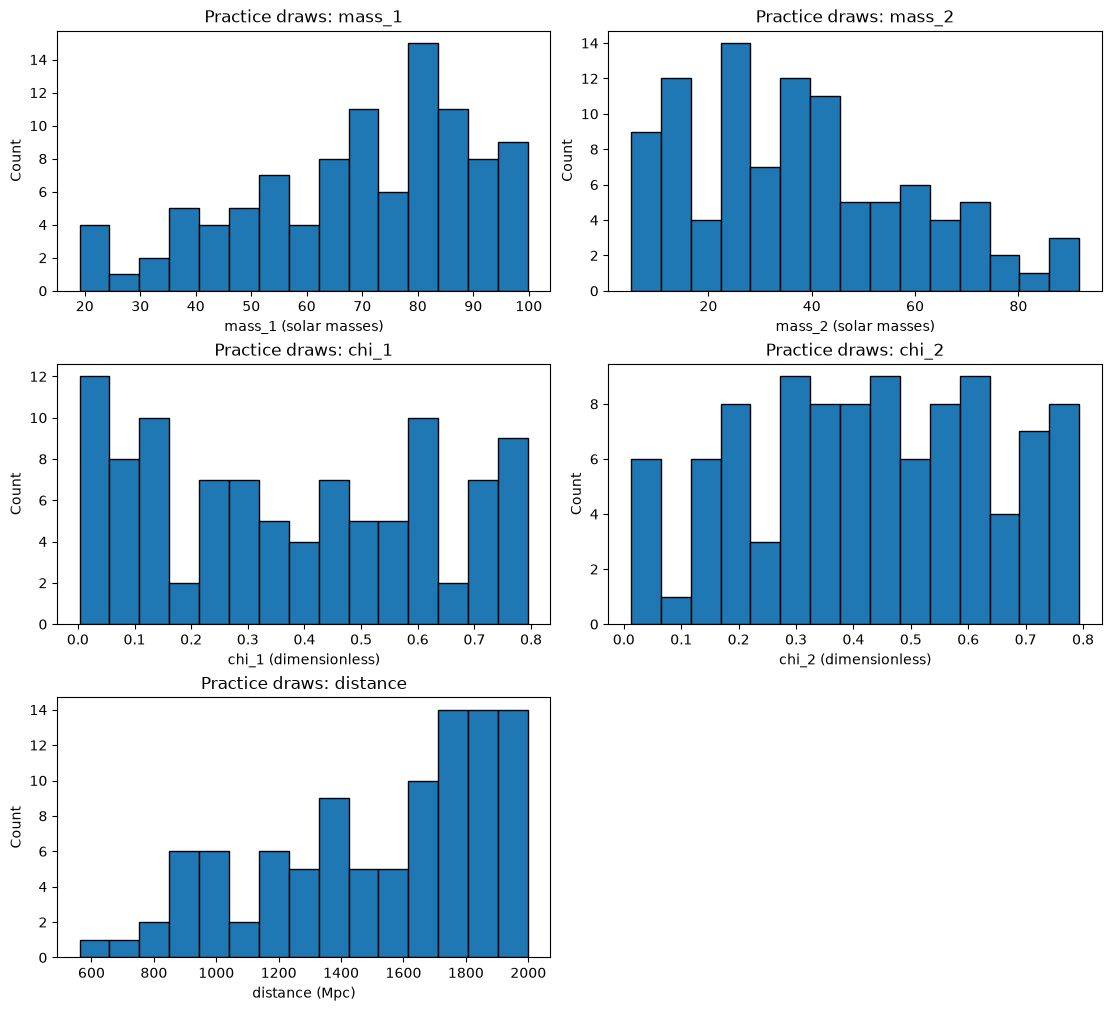

In [43]:
# to load noise from 01: noise = np.load(strain_path)
import numpy as np 
import pandas as pd 
from pycbc.waveform import get_td_waveform
import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")


SOLAR_MASS_RANGE = (5,100)
SPIN_RANGE = (0, 0.8)
DISTANCE_RANGE = (100, 2000)
SEED = 1234
N_PRACTICE_DRAWS = 100

random = np.random.default_rng(SEED)

'''
Create the priors table
'''

priors_table = {
    'Parameter': ['mass_1, mass_2', 'chi_1, chi_2', 'distance'],
    'minimum': [5,0,100],
    'maximum': [100,0.8,2000],
    'Units': ['solar masses', 'dimensionless', 'MPC'],
    'Distribution': ['Uniform component draws, then sorted', 'uniform', 'Euclidean volume weighted']
}

priors_table_df = pd.DataFrame(priors_table)
print(priors_table_df)

'''
Mass Function
'''

def sample_mass(n:int, minimum:int, maximum:int) -> np.array:
    return  np.random.uniform(low=minimum,high=maximum,size = n)

raw_m_1 = sample_mass(N_PRACTICE_DRAWS, SOLAR_MASS_RANGE[0], SOLAR_MASS_RANGE[1])
raw_m_2 = sample_mass(N_PRACTICE_DRAWS, SOLAR_MASS_RANGE[0], SOLAR_MASS_RANGE[1])

assert np.all((raw_m_1 >= SOLAR_MASS_RANGE[0]) & (raw_m_2 >= SOLAR_MASS_RANGE[0]))
assert np.all((raw_m_1 <= SOLAR_MASS_RANGE[1]) & (raw_m_2 <= SOLAR_MASS_RANGE[1]))

mass_1 = np.maximum(raw_m_1, raw_m_2)
mass_2 = np.minimum(raw_m_1, raw_m_2)

assert np.all(mass_1 >= mass_2)

'''
Spin Function
'''

def sample_chi(n:int, minimum:int, maximum:int): #chi = dimensionless spins
    return  np.random.uniform(low=minimum,high=maximum,size = n)

chi_1 = sample_chi(N_PRACTICE_DRAWS, SPIN_RANGE[0], SPIN_RANGE[1])
chi_2 = sample_chi(N_PRACTICE_DRAWS, SPIN_RANGE[0], SPIN_RANGE[1])

assert np.all((chi_1 >= SPIN_RANGE[0]) & (chi_2 >= SPIN_RANGE[0]))
assert np.all((chi_1 <= SPIN_RANGE[1]) & (chi_2 <= SPIN_RANGE[1]))

'''
Distance Function
'''

def sample_distance(n:int, minimum:int, maximum:int):
    u = np.random.uniform(0,1, size=n)
    return np.cbrt((u*(maximum**3 - minimum**3)) + minimum**3)

distance = sample_distance(N_PRACTICE_DRAWS, DISTANCE_RANGE[0], DISTANCE_RANGE[1])

assert np.all(distance >= 100)
assert np.all(distance <= 2000)

'''
Parameter Table
'''

params = {
    "draw_id": [f"practice-{i:03d}" for i in range(N_PRACTICE_DRAWS)],
    'mass_1': mass_1,
    'mass_2': mass_2,
    'chi_1': chi_1,
    'chi_2': chi_2,
    'distance': distance,
}

parameter_table = pd.DataFrame(params)
assert parameter_table.notna().all().all()

print(parameter_table.head())

import matplotlib.pyplot as plt

plot_columns = [
    "mass_1",
    "mass_2",
    "chi_1",
    "chi_2",
    "distance",
]

figure, axes = plt.subplots(
    3,
    2,
    figsize=(11, 10),
    constrained_layout=True,
)

units = {
    "mass_1": "solar masses",
    "mass_2": "solar masses",
    "chi_1": "dimensionless",
    "chi_2": "dimensionless",
    "distance": "Mpc",
}

for axis, column in zip(axes.flat, plot_columns):
    axis.hist(
        parameter_table[column],
        bins=15,
        edgecolor="black",
    )
    axis.set_title(f"Practice draws: {column}")
    axis.set_xlabel(f"{column} ({units[column]})")
    axis.set_ylabel("Count")

axes.flat[-1].axis("off")
plt.show()

**Cell 7**

### Your findings and contribution record

- What did you do personally, and on what date?
- What measured counts, plots or checks support your answer?
- What are the units, IDs and assumptions?
- What failed, remains planned or needs a teammate's input?
- What will you hand off?

**Your response:**

**Cell 8**

## Task 2: Explore waveform physics before injection

### Background knowledge
IMRPhenomD models aligned-spin inspiral, merger and ringdown. h_plus and h_cross are polarizations, not automatically the detector response. At fixed remaining parameters, amplitude scales approximately as 1/distance. For a learning pilot, using h_plus directly is a simplified convention that must be documented.

### Your task
Call the waveform library directly. Inspect time spacing, duration and peak location. Compare distances 100, 500 and 1000 Mpc with identical masses/spins and a common vertical scale. Vary mass separately. Agree on a fixed inclination/polarization convention; do not claim a full detector projection if you use plus-only.

### Evidence and completion checks
Clean-waveform comparison figure with correct time/strain axes and an explanation of amplitude versus timing changes.

**Cell 9 is your empty work cell.** Write your own implementation if this task needs code. For planning/writing-only tasks, leave it empty and complete your response below. Do not train a model merely to fill a cell.

**Cell 10**

### Your findings and contribution record

- What did you do personally, and on what date?
- What measured counts, plots or checks support your answer?
- What are the units, IDs and assumptions?
- What failed, remains planned or needs a teammate's input?
- What will you hand off?

**Your response:**

**Cell 11**

## Task 3: Derive the four targets

### Background knowledge
Chirp mass Mc = (m1*m2)^(3/5)/(m1+m2)^(1/5), mass ratio q = m2/m1, and effective spin chi_eff = (m1*chi1+m2*chi2)/(m1+m2). Distance is kept in Mpc. These labels come from the simulator, not measured noise.

### Your task
Compute the target table yourself. Audit mass ordering and formula results on a few simple manually checked cases. Preserve sample IDs and the shared target order. Explain why pure noise does not have a distance/mass label of zero.

### Evidence and completion checks
Finite target table with units, range checks and manually verified examples.

**Cell 12 is your empty work cell.** Write your own implementation if this task needs code. For planning/writing-only tasks, leave it empty and complete your response below. Do not train a model merely to fill a cell.

**Cell 13**

### Your findings and contribution record

- What did you do personally, and on what date?
- What measured counts, plots or checks support your answer?
- What are the units, IDs and assumptions?
- What failed, remains planned or needs a teammate's input?
- What will you hand off?

**Your response:**

**Cell 14**

## Task 4: Align and inject without changing source noise

### Background knowledge
Injection means y = n + h on a common time grid. Align the waveform peak, not its last sample, to the selected merger position. Ringdown continues after the peak. A sufficiently padded buffer lets preprocessing remove edge artifacts before the final crop.

### Your task
On a tiny practice buffer, demonstrate the placement indices. Then create a new copy of each real buffer, add the waveform, and retain the original noise unchanged. Check both waveform boundaries, crop clearance and nonoverlapping final windows. Preserve local and source indices. Inherit the source split and group.

### Evidence and completion checks
Aligned noise/waveform/injection plot, placement metadata and boundary checks.

**Cell 15 is your empty work cell.** Write your own implementation if this task needs code. For planning/writing-only tasks, leave it empty and complete your response below. Do not train a model merely to fill a cell.

**Cell 16**

### Your findings and contribution record

- What did you do personally, and on what date?
- What measured counts, plots or checks support your answer?
- What are the units, IDs and assumptions?
- What failed, remains planned or needs a teammate's input?
- What will you hand off?

**Your response:**

**Cell 17**

## Task 5: Compute SNR and track selection

### Background knowledge
Optimal SNR squared is 4 times the positive-frequency integral of |h_tilde(f)| squared / PSD(f). FFT normalization, sample spacing, frequency spacing and PSD units must agree. A waveform norm is not the same as a matched-filter search over noisy data. An SNR gate changes the accepted population.

### Your task
Use Role 3 PSDs to calculate optimal SNR. Implement a frequency-sum check and compare with a library calculation on one example. Specify low/high cutoffs separately from the preprocessing band; record any departure from the existing 20 Hz lower SNR cutoff. Apply an agreed threshold, such as 8, with a finite attempt budget. Count every attempted, accepted, rejected and failed draw by run and split.

### Evidence and completion checks
Validated SNR convention and complete selection ledger; insufficient accepted examples are reported rather than hidden.

**Cell 18 is your empty work cell.** Write your own implementation if this task needs code. For planning/writing-only tasks, leave it empty and complete your response below. Do not train a model merely to fill a cell.

**Cell 19**

### Your findings and contribution record

- What did you do personally, and on what date?
- What measured counts, plots or checks support your answer?
- What are the units, IDs and assumptions?
- What failed, remains planned or needs a teammate's input?
- What will you hand off?

**Your response:**

**Cell 20**

## Task 6: Export labels and analyze selection

### Background knowledge
Accepted injections are a selected population. Different PSDs can produce different rejection rates even with identical draw rules. Target correlations may arise from shared component parameters, not learned model importance.

### Your task
Export buffers/manifests/targets. Plot accepted target and SNR distributions by run; compare attempted versus accepted parameter draws where possible. Make a target correlation heatmap and a distance-SNR scatter plot. Interpret selection effects and confirm that Role 3 can reconstruct one buffer/time position. Prepare 150 words and a contribution log.

### Evidence and completion checks
Detailed population EDA, actual counts and an accepted-ID handoff; do not assert noise-induced drift from these plots alone.

**Cell 21 is your empty work cell.** Write your own implementation if this task needs code. For planning/writing-only tasks, leave it empty and complete your response below. Do not train a model merely to fill a cell.

**Cell 22**

### Your findings and contribution record

- What did you do personally, and on what date?
- What measured counts, plots or checks support your answer?
- What are the units, IDs and assumptions?
- What failed, remains planned or needs a teammate's input?
- What will you hand off?

**Your response:**

**Cell 23**

## Milestone completion and handoff

Before marking your role complete, show the teammate consuming your artifacts one real record and its provenance. Give them a settings file, retained/rejected counts and a short interpretation, not just an array. Check sample_id, noise_id, group_id, run, split and shape at the handoff. Save outputs under your role-owned folder for the same experiment_id.

Deliver your completed notebook, a contribution log, 100-150 words of findings, figures with descriptive titles/axes/units/legends/captions and an explicit list of unfinished checks. Do not copy another person's implementation into your notebook. Preserve the older notebooks and existing PDFs.

**Stop at this checkpoint:** dataset preparation, validated preprocessing and EDA, exact allocation tables and the three-algorithm methodology plan. Full linear/Ridge/SNPE training, final model ranking, posterior calibration results and 800-per-run manual regeneration are not mandatory tasks in this set. Feature importance remains an acknowledged rubric gap if deferred; the team must decide how to complete that requirement before submission rather than asserting full compliance.

**Write a final reflection:** What did you personally implement? What evidence supports it? Which decisions need another owner's agreement? Which findings belong to the new pilot rather than the historical project? What remains before submission?


**Cell 24**

## Background references

- [GWOSC data](https://gwosc.org/data/)
- [PyCBC waveforms](https://pycbc.org/pycbc/latest/html/waveform.html)
- [SciPy signal processing](https://docs.scipy.org/doc/scipy/reference/signal.html)
- [sbi calibration guide](https://sbi.readthedocs.io/en/latest/how_to_guide/16_sbc.html)

Consult library documentation for concepts and conventions. Your notebook should contain your own implementation and interpretation.